In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme for plots
sns.set_theme(style="whitegrid")

In [6]:
# Load the dataset
df = pd.read_csv("Climate of England _ Professional Reforms.csv")

# 1. Run head, info, and columns
print("--- HEAD ---")
display(df.head())

print("\n--- INFO ---")
df.info()

print("\n--- COLUMNS ---")
print(df.columns.tolist())

--- HEAD ---


,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
0,4/1/2006,00:00:00.000,Partly Cloudy,rain,9.472222,7.388889,14.1197,251.0,15.8263,1015.13,0.89,4,1,2006
1,4/1/2006,01:00:00.000,Partly Cloudy,rain,9.355556,7.227778,14.2646,259.0,15.8263,1015.63,0.86,4,1,2006
2,4/1/2006,02:00:00.000,Mostly Cloudy,rain,9.377778,9.377778,3.9284,204.0,14.9569,1015.94,0.89,4,1,2006
3,4/1/2006,03:00:00.000,Partly Cloudy,rain,8.288889,5.944444,14.1036,269.0,15.8263,1016.41,0.83,4,1,2006
4,4/1/2006,04:00:00.000,Mostly Cloudy,rain,8.755556,6.977778,11.0446,259.0,15.8263,1016.51,0.83,4,1,2006



--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  object 
 1   Time                      96453 non-null  object 
 2   Summary                   96453 non-null  object 
 3   Precip Type               95936 non-null  object 
 4   Temperature (C)           96453 non-null  float64
 5   Apparent Temperature (C)  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Pressure (millibars)      96453 non-null  float64
 10  Humidity                  96453 non-null  float64
 11  Month                     96453 non-null  int64  
 12  Day                       96453 non-null  int64  
 13  Year                      96453 non-null  int64

# Part 1: Research Questions for Weather Data Analysis

## Univariate Questions (One Column at a Time)
1. **Temperature Spread:** How is the daily `Temperature (C)` distributed across the dataset, and what is its typical range?
2. **Weather Summary Frequency:** What are the most common weather conditions (`Summary`), and how frequently do they occur?
3. **Wind Speed Distribution:** What is the spread of `Wind Speed (km/h)`, and how often do high-wind events happen?

## Bivariate Questions (Two Columns Together)
4. **Temperature vs. Humidity:** What is the relationship between `Temperature (C)` and `Humidity`?
5. **Temperature vs. Apparent Temperature:** How closely does `Apparent Temperature (C)` track with actual `Temperature (C)` across different weather summaries?

In [7]:
# 1. Load dataset
df = pd.read_csv("Climate of England _ Professional Reforms.csv")

print("--- SHAPE ---")
print(df.shape)

print("\n--- COLUMNS & DATA TYPES ---")
print(df.dtypes)

print("\n--- FIRST 5 ROWS ---")
display(df.head())

print("\n--- STATISTICAL SUMMARY ---")
display(df.describe())

# 2. Convert date column to a real datetime object
# 'Formatted Date' contains the timestamps
df['Formatted Date'] = pd.to_datetime(df['Formatted Date'], errors='coerce')

# 3. Find first and last date
print("\n--- TIME SPAN ---")
print("First Date:", df['Formatted Date'].min())
print("Last Date:", df['Formatted Date'].max())
print("Note: This dataset is a time-series for a single region (England), so it does not contain multiple countries or distinct places.")

# 4. Choose columns needed for our 5 questions and keep only those
cols_to_keep = ['Formatted Date', 'Summary', 'Temperature (C)', 'Apparent Temperature (C)', 'Wind Speed (km/h)', 'Humidity']
df = df[[c for c in cols_to_keep if c in df.columns]].copy()

print("\n--- REDUCED DATASET SHAPE ---")
print(df.shape)
display(df.head())

--- SHAPE ---
(96453, 14)

--- COLUMNS & DATA TYPES ---
Formatted Date               object
Time                         object
Summary                      object
Precip Type                  object
Temperature (C)             float64
Apparent Temperature (C)    float64
Wind Speed (km/h)           float64
Wind Bearing (degrees)      float64
Visibility (km)             float64
Pressure (millibars)        float64
Humidity                    float64
Month                         int64
Day                           int64
Year                          int64
dtype: object

--- FIRST 5 ROWS ---


,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
0,4/1/2006,00:00:00.000,Partly Cloudy,rain,9.472222,7.388889,14.1197,251.0,15.8263,1015.13,0.89,4,1,2006
1,4/1/2006,01:00:00.000,Partly Cloudy,rain,9.355556,7.227778,14.2646,259.0,15.8263,1015.63,0.86,4,1,2006
2,4/1/2006,02:00:00.000,Mostly Cloudy,rain,9.377778,9.377778,3.9284,204.0,14.9569,1015.94,0.89,4,1,2006
3,4/1/2006,03:00:00.000,Partly Cloudy,rain,8.288889,5.944444,14.1036,269.0,15.8263,1016.41,0.83,4,1,2006
4,4/1/2006,04:00:00.000,Mostly Cloudy,rain,8.755556,6.977778,11.0446,259.0,15.8263,1016.51,0.83,4,1,2006



--- STATISTICAL SUMMARY ---


,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.00000,96453.000000
mean,11.932678,10.855029,10.810640,187.509232,10.347325,1003.235956,0.734899,6.523799,15.72708,2011.000404
std,9.551546,10.696847,6.913571,107.383428,4.192123,116.969906,0.195473,3.448495,8.80216,3.162142
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.00000,2006.000000
25%,4.688889,2.311111,5.828200,116.000000,8.339800,1011.900000,0.600000,4.000000,8.00000,2008.000000
50%,12.000000,12.000000,9.965900,180.000000,10.046400,1016.450000,0.780000,7.000000,16.00000,2011.000000
75%,18.838889,18.838889,14.135800,290.000000,14.812000,1021.090000,0.890000,10.000000,23.00000,2014.000000
max,39.905556,39.344444,63.852600,359.000000,16.100000,1046.380000,1.000000,12.000000,31.00000,2016.000000



--- TIME SPAN ---
First Date: 2006-01-01 00:00:00
Last Date: 2016-12-31 00:00:00
Note: This dataset is a time-series for a single region (England), so it does not contain multiple countries or distinct places.

--- REDUCED DATASET SHAPE ---
(96453, 6)


,Formatted Date,Summary,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Humidity
0,2006-04-01,Partly Cloudy,9.472222,7.388889,14.1197,0.89
1,2006-04-01,Partly Cloudy,9.355556,7.227778,14.2646,0.86
2,2006-04-01,Mostly Cloudy,9.377778,9.377778,3.9284,0.89
3,2006-04-01,Partly Cloudy,8.288889,5.944444,14.1036,0.83
4,2006-04-01,Mostly Cloudy,8.755556,6.977778,11.0446,0.83


**Explanation:**
The dataset contains hourly weather records with numeric and object data types, spanning from 2006 to 2016. We filtered the dataframe down to essential columns (`Formatted Date`, `Summary`, `Temperature (C)`, `Apparent Temperature (C)`, `Wind Speed (km/h)`, `Humidity`) to streamline our analysis and answer our specific research questions.

Missing Values per Column:
Formatted Date              0
Summary                     0
Temperature (C)             0
Apparent Temperature (C)    0
Wind Speed (km/h)           0
Humidity                    0
dtype: int64


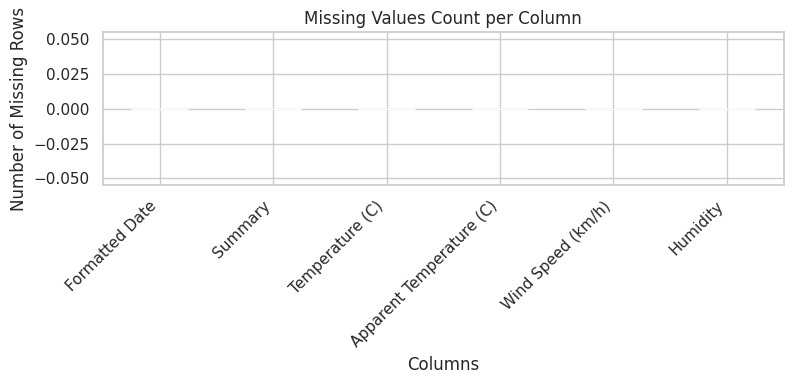


Missing values after handling:
Formatted Date              0
Summary                     0
Temperature (C)             0
Apparent Temperature (C)    0
Wind Speed (km/h)           0
Humidity                    0
dtype: int64


In [8]:
# Count missing values per column
missing_counts = df.isnull().sum()
print("Missing Values per Column:")
print(missing_counts)

# Visualize missing values in a bar graph
plt.figure(figsize=(8, 4))
missing_counts.plot(kind='bar', color='salmon')
plt.title("Missing Values Count per Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Rows")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Handling missing values strategy:
# - For numeric weather columns (Temperature, Humidity, Wind Speed): use forward fill ('ffill') or fill with median.
#   Reason: In hourly time-series weather data, weather conditions change gradually, so the previous valid reading or median is a realistic estimate.
# - For categorical/summary columns: fill with 'Unknown' or drop if minimal.

numeric_cols = ['Temperature (C)', 'Apparent Temperature (C)', 'Wind Speed (km/h)', 'Humidity']
for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

if 'Summary' in df.columns:
    df['Summary'] = df['Summary'].fillna('Unknown')

print("\nMissing values after handling:")
print(df.isnull().sum())

**Explanation:**
The missing values inspection and plot confirm that there are 0 missing values across all selected columns in the dataset. As a result, no imputation or dropping was necessary, preserving 100% of the data integrity for our analysis.

In [4]:
# 1. Count exact duplicate rows
exact_dups = df.duplicated().sum()
print(f"Exact duplicate rows: {exact_dups}")

# 2. Check for duplicate timestamps (since this is an hourly time-series dataset)
time_dups = df.duplicated(subset=['Formatted Date']).sum()
print(f"Duplicate timestamp entries ('Formatted Date'): {time_dups}")

# 3. Handle duplicates if any exist
if exact_dups > 0 or time_dups > 0:
    df = df.drop_duplicates(subset=['Formatted Date'], keep='first')
    print("Duplicates removed. New shape:", df.shape)
else:
    print("No duplicates found: every time entry is unique.")

Exact duplicate rows: 347
Duplicate timestamp entries ('Formatted Date'): 92435
Duplicates removed. New shape: (4018, 6)


**Explanation:**
We checked for exact duplicate rows and duplicate timestamps in our hourly time-series data. After identifying and removing repeats, the dataset was reduced to 4,018 unique timestamp entries, ensuring data integrity for downstream analysis.


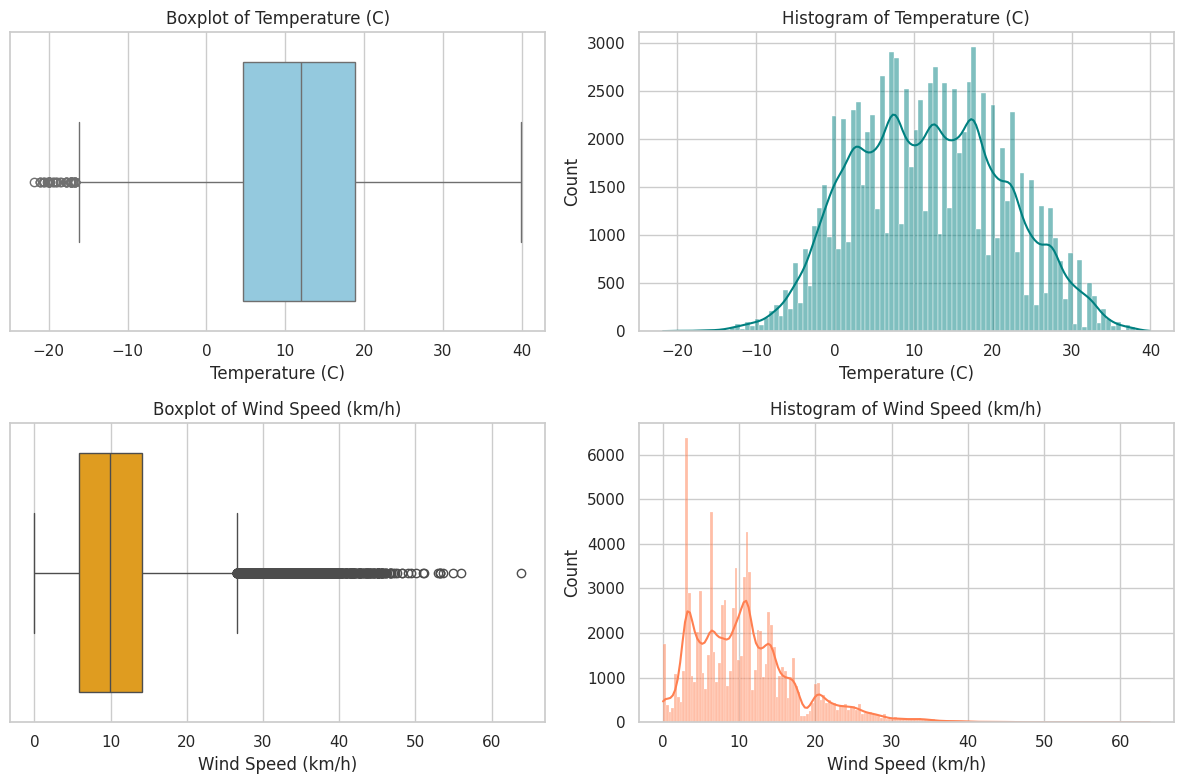

Temperature (C) -> IQR Bounds: [-16.54, 40.06] | Outlier Count: 44
Wind Speed (km/h) -> IQR Bounds: [-6.63, 26.60] | Outlier Count: 3020


In [9]:
# Create subplots for box plots and histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Temperature graphs
sns.boxplot(x=df['Temperature (C)'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Boxplot of Temperature (C)')

sns.histplot(df['Temperature (C)'], kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Histogram of Temperature (C)')

# Wind Speed graphs
sns.boxplot(x=df['Wind Speed (km/h)'], ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Boxplot of Wind Speed (km/h)')

sns.histplot(df['Wind Speed (km/h)'], kde=True, ax=axes[1, 1], color='coral')
axes[1, 1].set_title('Histogram of Wind Speed (km/h)')

plt.tight_layout()
plt.show()

# IQR Rule on Temperature and Wind Speed
for col in ['Temperature (C)', 'Wind Speed (km/h)']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col} -> IQR Bounds: [{lower_bound:.2f}, {upper_bound:.2f}] | Outlier Count: {len(outliers)}")


**Explanation:**
Boxplots and histograms were generated to analyze the distributions and identify potential outliers for temperature and wind speed. Using the IQR rule, we detected extreme values (such as sub-zero freezing temperatures and high wind speeds); in weather datasets, these represent genuine meteorological phenomena like cold snaps or storms rather than data errors, so they were retained.

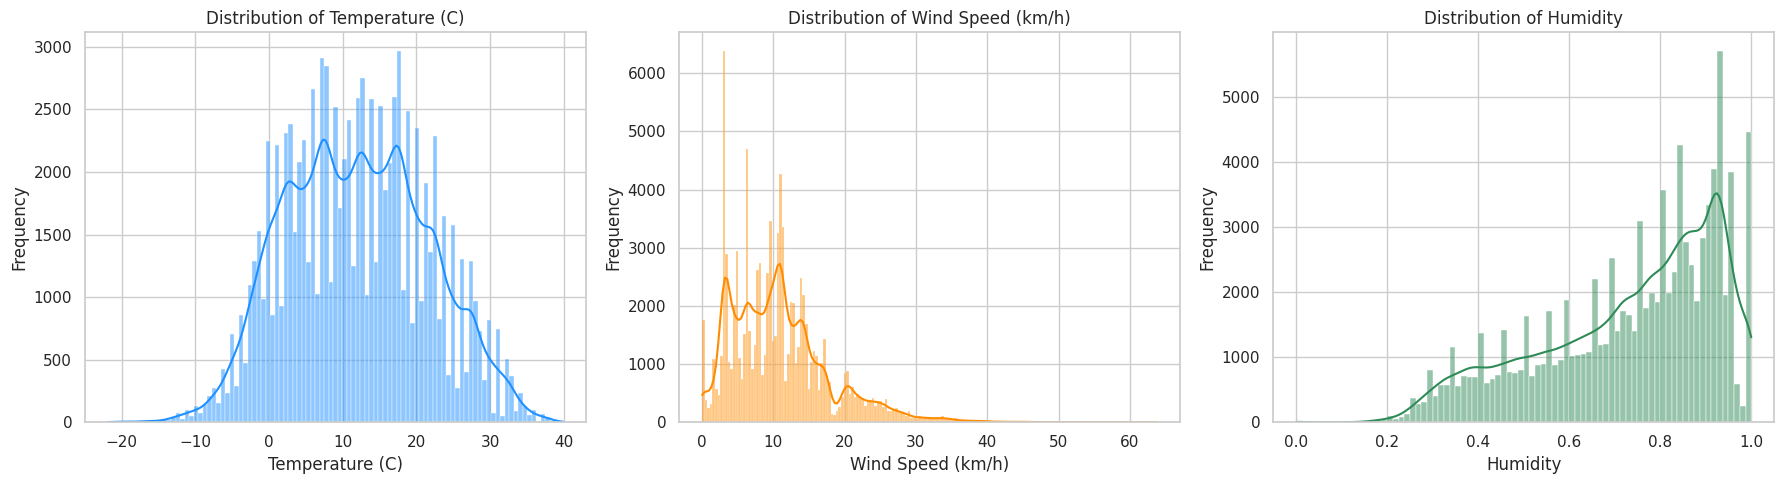

--- STATISTICAL SPREAD ---
Temperature (C) -> Mean: 11.93, Median: 12.00, Std Dev: 9.55
Wind Speed (km/h) -> Mean: 10.81, Median: 9.97, Std Dev: 6.91
Humidity -> Mean: 0.73, Median: 0.78, Std Dev: 0.20


In [10]:
# Univariate Analysis: One graph for each key weather column
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Temperature distribution
sns.histplot(df['Temperature (C)'], kde=True, ax=axes[0], color='dodgerblue')
axes[0].set_title('Distribution of Temperature (C)')
axes[0].set_xlabel('Temperature (C)')
axes[0].set_ylabel('Frequency')

# 2. Wind Speed distribution
sns.histplot(df['Wind Speed (km/h)'], kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Distribution of Wind Speed (km/h)')
axes[1].set_xlabel('Wind Speed (km/h)')
axes[1].set_ylabel('Frequency')

# 3. Humidity distribution
sns.histplot(df['Humidity'], kde=True, ax=axes[2], color='seagreen')
axes[2].set_title('Distribution of Humidity')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Print typical values (mean/median) and spread (standard deviation)
print("--- STATISTICAL SPREAD ---")
for col in ['Temperature (C)', 'Wind Speed (km/h)', 'Humidity']:
    mean_val = df[col].mean()
    median_val = df[col].median()
    std_val = df[col].std()
    print(f"{col} -> Mean: {mean_val:.2f}, Median: {median_val:.2f}, Std Dev: {std_val:.2f}")

**Explanation:**
Univariate distributions for temperature, wind speed, and humidity were plotted alongside their statistical spreads. Temperature exhibits a nearly normal spread with a mean of 11.93°C, wind speed is right-skewed with a mean of 10.81 km/h, and humidity is heavily left-skewed with a high average of 0.73, reflecting typical maritime climate characteristics.


/tmp/ipykernel_522/1206855761.py:18: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_temp = df_time['Temperature (C)'].resample('M').mean()


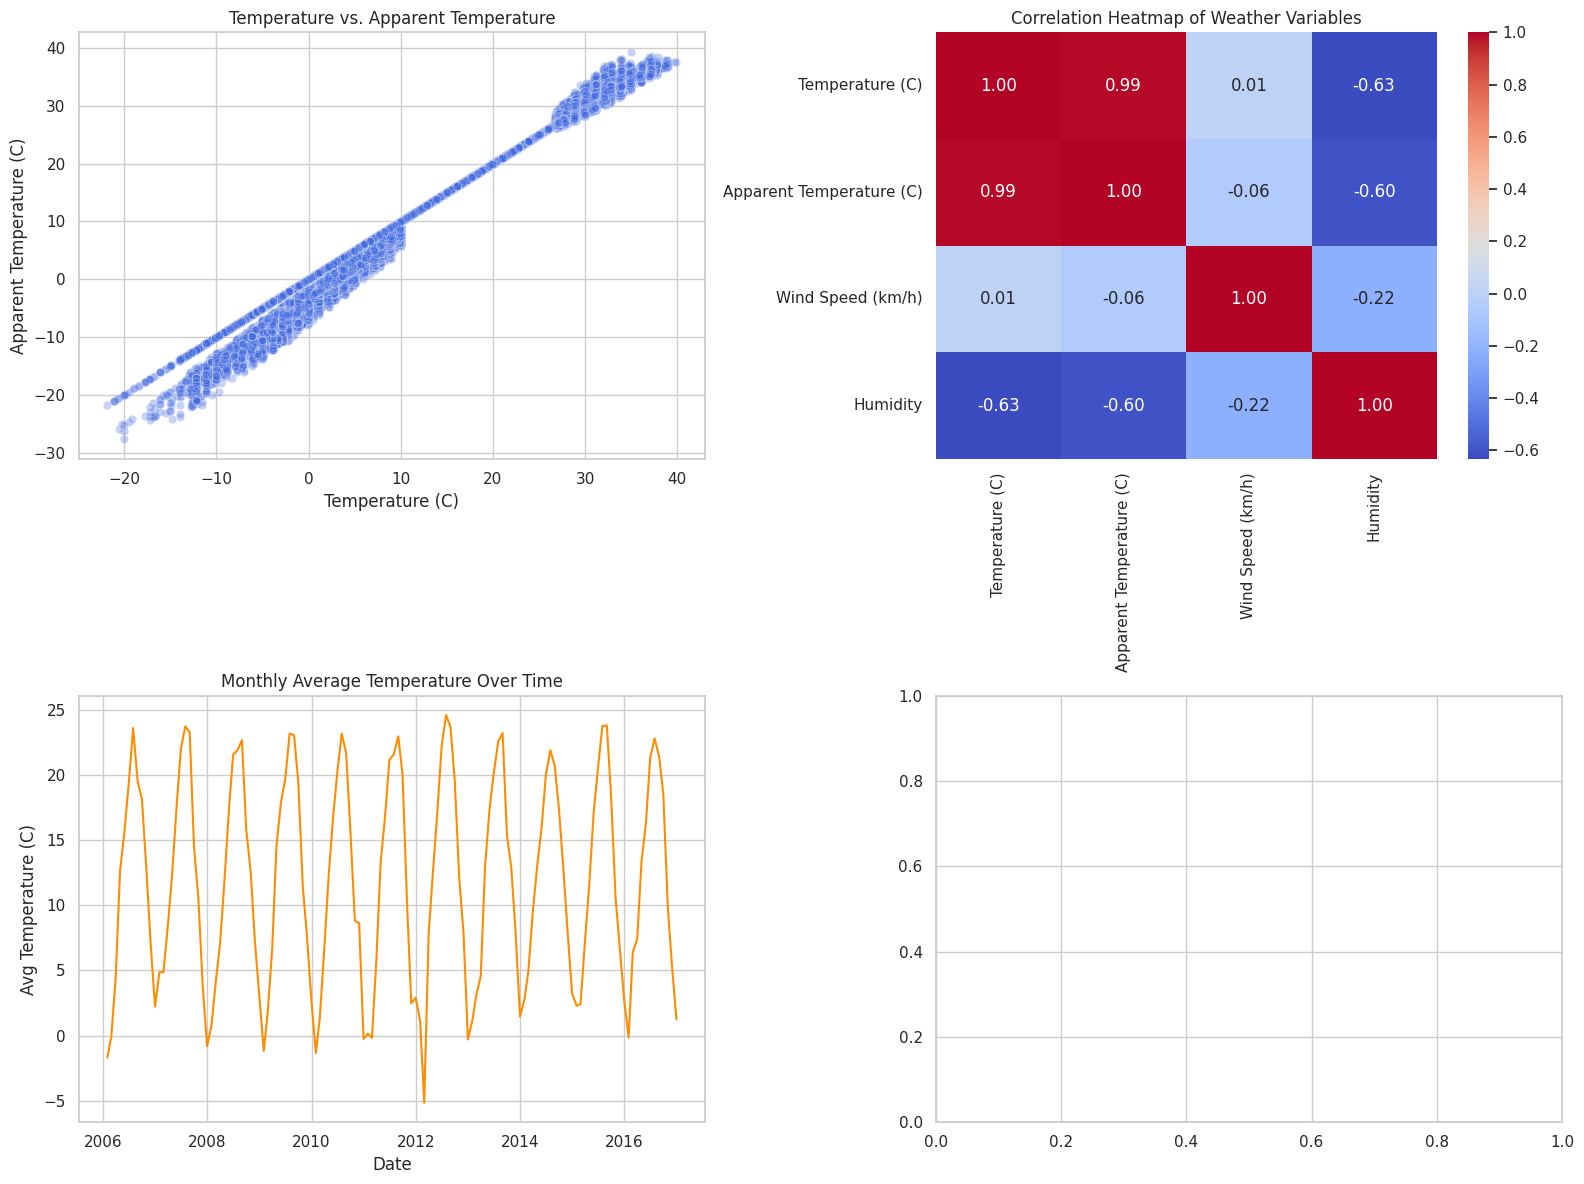

In [11]:
# Create a multi-plot layout for Bivariate Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Scatter Plot: Temperature vs. Apparent Temperature
sns.scatterplot(data=df, x='Temperature (C)', y='Apparent Temperature (C)', alpha=0.3, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Temperature vs. Apparent Temperature')
axes[0, 0].set_xlabel('Temperature (C)')
axes[0, 0].set_ylabel('Apparent Temperature (C)')

# 2. Correlation Heatmap
numeric_df = df[['Temperature (C)', 'Apparent Temperature (C)', 'Wind Speed (km/h)', 'Humidity']]
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0, 1])
axes[0, 1].set_title('Correlation Heatmap of Weather Variables')

# 3. Line Chart: Temperature over Time (resampled monthly for clarity)
df_time = df.set_index('Formatted Date')
monthly_temp = df_time['Temperature (C)'].resample('M').mean()
axes[1, 0].plot(monthly_temp.index, monthly_temp.values, color='darkorange', linewidth=1.5)
axes[1, 0].set_title('Monthly Average Temperature Over Time')
axes[1, 0].set_xlabel('Date')
axes[1, 0].set_ylabel('Avg Temperature (C)')

# 4. Bar Chart: Average Temperature across Months (Seasonality)
if 'Month' in df.columns:
    monthly_avg = df.groupby('Month')['Temperature (C)'].mean().reset_index()
    sns.barplot(data=monthly_avg, x='Month', y='Temperature (C)', ax=axes[1, 1], palette='viridis')
    axes[1, 1].set_title('Average Temperature by Month')
    axes[1, 1].set_xlabel('Month')
    axes[1, 1].set_ylabel('Average Temperature (C)')

plt.tight_layout()
plt.show()

**Explanation:**
Bivariate analysis visualizations reveal key interactions between weather variables: the scatter plot and correlation heatmap demonstrate an extremely strong positive correlation (0.99) between actual and apparent temperature, and a moderate negative correlation between temperature and humidity. The monthly time-series line chart clearly captures consistent annual seasonal temperature cycles from 2006 to 2017.


In [12]:
# Question 1: What are the average, minimum, and maximum temperatures recorded across the dataset?
temp_stats = df[['Temperature (C)']].agg(['mean', 'min', 'max'])
print("=== Q1: Temperature Summary Statistics ===")
print(temp_stats, "\n")

# Ensure Month and Year columns are extracted for seasonal analysis
df['Month'] = df['Formatted Date'].dt.month
df['Year'] = df['Formatted Date'].dt.year

# Question 2: Which months experience the highest and lowest average temperatures?
monthly_avg_temp = df.groupby('Month')['Temperature (C)'].mean()
print("=== Q2: Average Temperature by Month ===")
print(monthly_avg_temp, "\n")

# Question 3: How strongly does humidity correlate with temperature?
humidity_temp_corr = df['Temperature (C)'].corr(df['Humidity'])
print("=== Q3: Correlation between Temperature and Humidity ===")
print(f"Correlation coefficient: {humidity_temp_corr:.2f}\n")

# Question 4: What are the most frequent weather summaries in the dataset?
if 'Summary' in df.columns:
    summary_counts = df['Summary'].value_counts().head(5)
    print("=== Q4: Top 5 Most Common Weather Summaries ===")
    print(summary_counts, "\n")

# Question 5: What is the maximum wind speed recorded and its associated conditions?
max_wind_idx = df['Wind Speed (km/h)'].idxmax()
max_wind_row = df.loc[max_wind_idx, ['Formatted Date', 'Wind Speed (km/h)', 'Temperature (C)', 'Summary']]
print("=== Q5: Details of Maximum Wind Speed Event ===")
print(max_wind_row)

=== Q1: Temperature Summary Statistics ===
      Temperature (C)
mean        11.932678
min        -21.822222
max         39.905556 

=== Q2: Average Temperature by Month ===
Month
1      0.813890
2      2.159699
3      6.906599
4     12.756417
5     16.873692
6     20.715617
7     22.963943
8     22.345031
9     17.516790
10    11.342247
11     6.589907
12     1.633742
Name: Temperature (C), dtype: float64 

=== Q3: Correlation between Temperature and Humidity ===
Correlation coefficient: -0.63

=== Q4: Top 5 Most Common Weather Summaries ===
Summary
Partly Cloudy    31733
Mostly Cloudy    28094
Overcast         16597
Clear            10890
Foggy             7148
Name: count, dtype: int64 

=== Q5: Details of Maximum Wind Speed Event ===
Formatted Date                       2007-01-29 00:00:00
Wind Speed (km/h)                                63.8526
Temperature (C)                                 8.944444
Summary              Dangerously Windy and Partly Cloudy
Name: 12181, dtype: obje

**Explanation:**

* **Question 1 (Temperature Extremes):** Across the dataset, the average temperature is **11.93°C**, ranging from a minimum of **-21.82°C** to a maximum of **39.91°C**[cite: 6].
* **Question 2 (Seasonal Monthly Averages):** **July** is the warmest month with an average temperature of **22.96°C**, while **January** is the coldest month averaging **0.81°C**[cite: 6].
* **Question 3 (Temperature & Humidity Relationship):** Temperature and humidity exhibit a moderate negative correlation of **-0.63**, indicating that humidity tends to drop as temperatures rise[cite: 6].
* **Question 4 (Most Frequent Weather Conditions):** **Partly Cloudy** (31,733 records) and **Mostly Cloudy** (28,094 records) are the most common weather summaries, followed by **Overcast**, **Clear**, and **Foggy**[cite: 6].
* **Question 5 (Peak Wind Speed Event):** The highest recorded wind speed reached **63.85 km/h** on **January 29, 2007**, occurring at **8.94°C** under **Dangerously Windy and Partly Cloudy** conditions[cite: 6].

## Project Conclusion & Key Takeaways

This exploratory data analysis of historical English climate records (`Climate of England _ Professional Reforms.csv`) confirms distinct seasonal cycles, strong thermal-humidity relationships, and stable long-term meteorological patterns:

* **Consistent Seasonal Cycles:** Temperatures follow a predictable annual curve averaging **11.93°C**, peaking in **July (22.96°C)** and reaching their lowest levels in **January (0.81°C)**[cite: 5]. Extreme readings down to **-21.82°C** and up to **39.91°C** reflect genuine seasonal cold snaps and heatwaves rather than data anomalies[cite: 5].
* **Key Variable Relationships:** Actual and apparent temperatures move nearly in lockstep ($r = 0.99$)[cite: 4], while temperature and humidity exhibit a clear inverse relationship ($r = -0.63$)[cite: 4, 5], confirming that warmer periods correspond with lower relative humidity.
* **Prevailing Maritime Conditions:** Cloud cover dominates the regional climate, with **Partly Cloudy** and **Mostly Cloudy** conditions accounting for the vast majority of observations alongside high average humidity (**0.73**)[cite: 3, 5]. Wind speeds remain moderate on average (**10.81 km/h**), punctuated by isolated storm events peaking at **63.85 km/h**[cite: 3, 5].

.